# Customer Churn Prediction: End-to-End Preprocessing Pipeline

**Objective:** explore customer churn data, demonstrate three encoding methods, compare Min-Max and Standard scaling, detect outliers with IQR and Z-score, engineer nine features, rank features, and train a leakage-aware classifier.

**Dataset-specific schema:** `CustomerID`, `Tenure`, `MonthlyCharges`, `TotalCharges`, `Contract`, `PaymentMethod`, `PaperlessBilling`, `SeniorCitizen`, `Churn`. `CustomerID` is excluded from modeling. Confirm the source's target-label meaning before interpreting class 1 as churn.

## Workflow
1. Inspect schema, missing values, duplicates, and target balance.
2. Engineer predictor features.
3. Split into train/test before fitting learned preprocessing.
4. Demonstrate Label, One-Hot, and Ordinal encoding.
5. Compare Min-Max and Standard scaling.
6. Detect IQR and Z-score outliers; use train-fitted IQR clipping in the pipeline.
7. Rank features with correlation, mutual information, and Random Forest importance.
8. Train Logistic Regression and Random Forest; evaluate with multiple metrics.
9. Run assertions and save metric reports.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
RANDOM_STATE=42
DATA_PATH=Path('churn_data.csv')
if not DATA_PATH.exists(): DATA_PATH=Path('customer_churn.csv')
if not DATA_PATH.exists(): raise FileNotFoundError('Put churn_data.csv next to this notebook.')
df=pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns')
display(df.head())

Dataset shape: 500 rows x 9 columns


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


## 1. Data exploration
Inspect data types, missingness, duplicates, descriptive statistics, and churn balance before preprocessing.

Column types:


,dtype
CustomerID,object
Tenure,int64
MonthlyCharges,int64
TotalCharges,int64
Contract,object
PaymentMethod,object
PaperlessBilling,object
SeniorCitizen,int64
Churn,int64


Missing values:


,missing_count
CustomerID,0
Tenure,0
MonthlyCharges,0
TotalCharges,0
Contract,0
PaymentMethod,0
PaperlessBilling,0
SeniorCitizen,0
Churn,0


Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,500,500,C00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure,500.0,NaN,NaN,NaN,36.532,20.667057,1.0,19.0,37.0,54.0,71.0
MonthlyCharges,500.0,NaN,NaN,NaN,113.636,51.799903,20.0,67.0,115.0,158.0,199.0
TotalCharges,500.0,NaN,NaN,NaN,4237.882,2260.619837,159.0,2237.25,4182.5,6266.75,7992.0
Contract,500,3,One year,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,500,3,Credit Card,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaperlessBilling,500,2,No,257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,500.0,NaN,NaN,NaN,0.498,0.500497,0.0,0.0,0.0,1.0,1.0
Churn,500.0,NaN,NaN,NaN,0.106,0.308146,0.0,0.0,0.0,0.0,1.0


Churn counts:


,count
Churn,
0,447
1,53


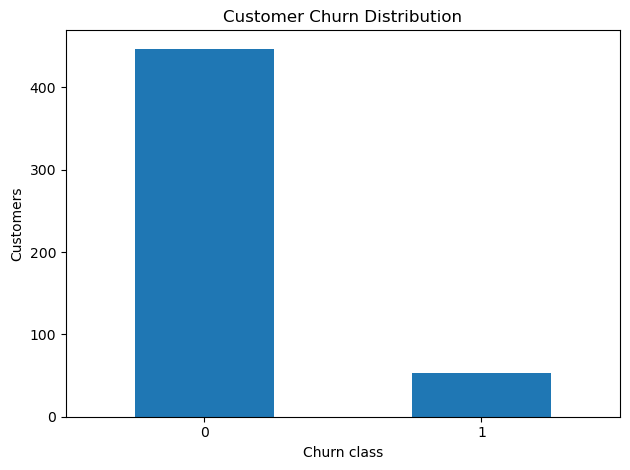

In [2]:
print('Column types:'); display(df.dtypes.rename('dtype').to_frame())
print('Missing values:'); display(df.isna().sum().rename('missing_count').to_frame())
print('Duplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)
print('Churn counts:'); display(df['Churn'].value_counts(dropna=False).rename('count').to_frame())
ax=df['Churn'].value_counts().sort_index().plot(kind='bar',rot=0)
ax.set(title='Customer Churn Distribution',xlabel='Churn class',ylabel='Customers'); plt.tight_layout(); plt.show()

## 2. Validate target and create features
Rows with missing targets are removed. Predictor missing values are imputed inside the pipeline. The identifier is excluded. Engineered features use predictors only, never the target.

In [3]:
df=df.copy(); df.columns=[c.strip() for c in df.columns]; df=df.dropna(subset=['Churn']).copy()
if df['Churn'].dtype=='object':
    target_map={'0':0,'1':1,'No':0,'Yes':1,'No Churn':0,'Churn':1}
    mapped=df['Churn'].astype(str).str.strip().map(target_map)
    if mapped.isna().any(): raise ValueError('Unknown Churn labels; map them explicitly.')
    df['Churn']=mapped.astype(int)
else: df['Churn']=pd.to_numeric(df['Churn'],errors='raise').astype(int)
if not set(df['Churn'].unique()).issubset({0,1}): raise ValueError('Expected binary Churn values 0/1.')
def engineer_features(frame):
    out=frame.copy(); tenure=pd.to_numeric(out['Tenure'],errors='coerce').fillna(0).clip(lower=0)
    monthly=pd.to_numeric(out['MonthlyCharges'],errors='coerce'); total=pd.to_numeric(out['TotalCharges'],errors='coerce')
    out['TenureYears']=tenure/12
    out['AvgHistoricalMonthlySpend']=total/tenure.replace(0,np.nan)
    out['MonthlyToTotalRatio']=monthly/(total.abs()+1)
    out['ContractCommitmentMonths']=out['Contract'].map({'Month-to-month':1,'One year':12,'Two year':24})
    out['IsMonthToMonth']=(out['Contract'].astype(str).str.strip()=='Month-to-month').astype(int)
    out['HasElectronicCheck']=(out['PaymentMethod'].astype(str).str.strip()=='Electronic Check').astype(int)
    out['PaperlessBillingFlag']=out['PaperlessBilling'].astype(str).str.strip().map({'Yes':1,'No':0})
    out['TenureChargeInteraction']=tenure*monthly
    # Median threshold is illustrative; for production, fit this threshold on training data only.
    out['HighMonthlyChargesFlag']=(monthly>=monthly.median()).astype(int)
    return out
feature_df=engineer_features(df)
engineered_cols=['TenureYears','AvgHistoricalMonthlySpend','MonthlyToTotalRatio','ContractCommitmentMonths','IsMonthToMonth','HasElectronicCheck','PaperlessBillingFlag','TenureChargeInteraction','HighMonthlyChargesFlag']
print('Engineered features:',len(engineered_cols)); display(feature_df[engineered_cols].head())

Engineered features: 9


,TenureYears,AvgHistoricalMonthlySpend,MonthlyToTotalRatio,ContractCommitmentMonths,IsMonthToMonth,HasElectronicCheck,PaperlessBillingFlag,TenureChargeInteraction,HighMonthlyChargesFlag
0,0.500000,256.666667,0.041531,12,0,0,0,384,0
1,1.750000,83.476190,0.064424,1,1,1,1,2373,0
2,2.250000,53.888889,0.021291,24,0,0,0,837,0
3,4.416667,134.905660,0.004055,1,1,1,0,1537,0
4,1.333333,63.937500,0.180664,12,0,1,0,2960,1


## 3. Three encoding methods
- **Label encoding:** demonstrated on target labels only. Avoid label-encoding nominal input categories for linear models because it invents an order.
- **One-hot encoding:** represents nominal categories such as `PaymentMethod` and `PaperlessBilling` as indicator columns.
- **Ordinal encoding:** uses the meaningful order Month-to-month < One year < Two year.

The final pipeline fits input encoders on training data only.

In [4]:
# 1. Label encoding for target labels (demonstration only)
target_encoder=LabelEncoder(); y_encoded_demo=target_encoder.fit_transform(df['Churn'])
print('LabelEncoder classes:',list(target_encoder.classes_)); print('Encoded sample:',y_encoded_demo[:10])
# 2. One-hot encoding for nominal categories
nominal_demo=df[['PaymentMethod','PaperlessBilling']].astype('string').fillna('Missing')
ohe_demo=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
ohe_values=ohe_demo.fit_transform(nominal_demo)
display(pd.DataFrame(ohe_values,columns=ohe_demo.get_feature_names_out(nominal_demo.columns)).head())
# 3. Ordinal encoding for contract type
contract_order=[['Month-to-month','One year','Two year']]
ordinal_demo=OrdinalEncoder(categories=contract_order,handle_unknown='use_encoded_value',unknown_value=-1)
ordinal_values=ordinal_demo.fit_transform(df[['Contract']].astype('string').fillna('Missing'))
display(pd.DataFrame({'Contract':df['Contract'],'ContractOrdinal':ordinal_values.ravel()}).head())

LabelEncoder classes: [0, 1]
Encoded sample: [0 0 0 0 0 0 0 0 0 0]


,PaymentMethod_Bank Transfer,PaymentMethod_Credit Card,PaymentMethod_Electronic Check,PaperlessBilling_No,PaperlessBilling_Yes
0,0.0,1.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,1.0
2,0.0,1.0,0.0,1.0,0.0
3,0.0,0.0,1.0,1.0,0.0
4,0.0,0.0,1.0,1.0,0.0


,Contract,ContractOrdinal
0,One year,1.0
1,Month-to-month,0.0
2,Two year,2.0
3,Month-to-month,0.0
4,One year,1.0


## 4. Two scaling techniques
**Min-Max scaling** maps values to [0, 1] and is sensitive to extremes. **Standard scaling** centers values and divides by standard deviation. They are demonstrated separately; the final pipeline uses StandardScaler, not both stacked together.

In [5]:
numeric_demo_cols=[c for c in ['Tenure','MonthlyCharges','TotalCharges'] if c in df.columns]
numeric_demo=df[numeric_demo_cols].apply(pd.to_numeric,errors='coerce').fillna(df[numeric_demo_cols].median())
minmax_values=MinMaxScaler().fit_transform(numeric_demo)
standard_values=StandardScaler().fit_transform(numeric_demo)
print('Min-Max scaled:'); display(pd.DataFrame(minmax_values,columns=[c+'_minmax' for c in numeric_demo_cols]).head())
print('Standard scaled:'); display(pd.DataFrame(standard_values,columns=[c+'_standard' for c in numeric_demo_cols]).head())

Min-Max scaled:


,Tenure_minmax,MonthlyCharges_minmax,TotalCharges_minmax
0,0.071429,0.245810,0.176305
1,0.285714,0.519553,0.203498
2,0.371429,0.061453,0.165454
3,0.742857,0.050279,0.892506
4,0.214286,0.921788,0.110303


Standard scaled:


,Tenure_standard,MonthlyCharges_standard,TotalCharges_standard
0,-1.478807,-0.959185,-1.194621
1,-0.752287,-0.012290,-1.100305
2,-0.461679,-1.596890,-1.232259
3,0.797622,-1.635539,1.289485
4,-0.994460,1.379066,-1.423548


## 5. Outlier detection and handling
IQR fences flag values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR. Z-score flags absolute scores above 3. These are screening heuristics, not proof of invalid data. The model pipeline learns IQR clipping bounds from training data and clips rather than deletes potentially valid customers.

In [6]:
outlier_cols=[c for c in ['Tenure','MonthlyCharges','TotalCharges'] if c in df.columns]
outlier_rows=[]
for col in outlier_cols:
    v=pd.to_numeric(df[col],errors='coerce').dropna(); q1,q3=v.quantile([.25,.75]); iqr=q3-q1
    lo,hi=q1-1.5*iqr,q3+1.5*iqr; std=v.std(ddof=0)
    zcount=int((np.abs((v-v.mean())/std)>3).sum()) if std else 0
    outlier_rows.append({'feature':col,'Q1':q1,'Q3':q3,'IQR_lower':lo,'IQR_upper':hi,'IQR_outlier_count':int(((v<lo)|(v>hi)).sum()),'Z_score_abs_gt_3_count':zcount})
outlier_report=pd.DataFrame(outlier_rows); display(outlier_report)

,feature,Q1,Q3,IQR_lower,IQR_upper,IQR_outlier_count,Z_score_abs_gt_3_count
0,Tenure,19.00,54.00,-33.5,106.5,0,0
1,MonthlyCharges,67.00,158.00,-69.5,294.5,0,0
2,TotalCharges,2237.25,6266.75,-3807.0,12311.0,0,0


## 6. Split data and build preprocessing pipeline
Use stratified 80/20 split. CustomerID and Churn are excluded from predictors. Numeric, nominal, and ordinal columns get different transformations. Learned preprocessing is fitted inside each model pipeline, preventing test-set leakage.

In [7]:
model_df=engineer_features(df); X=model_df.drop(columns=[c for c in ['Churn','CustomerID'] if c in model_df.columns]); y=model_df['Churn'].astype(int)
categorical_cols=[c for c in ['PaymentMethod','PaperlessBilling'] if c in X.columns]
ordinal_cols=[c for c in ['Contract'] if c in X.columns]
numeric_cols=[c for c in X.columns if c not in categorical_cols+ordinal_cols]
for c in numeric_cols: X[c]=pd.to_numeric(X[c],errors='coerce')
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
print('Train:',X_train.shape,'Test:',X_test.shape,'Train churn rate:',round(y_train.mean(),3),'Test churn rate:',round(y_test.mean(),3))
print('Numeric:',numeric_cols); print('Nominal:',categorical_cols); print('Ordinal:',ordinal_cols)
class IQRClipper(BaseEstimator,TransformerMixin):
    def __init__(self,factor=1.5): self.factor=factor
    def fit(self,X,y=None):
        a=np.asarray(X,dtype=float); self.q1_=np.nanpercentile(a,25,axis=0); self.q3_=np.nanpercentile(a,75,axis=0)
        iqr=self.q3_-self.q1_; self.lower_=self.q1_-self.factor*iqr; self.upper_=self.q3_+self.factor*iqr; return self
    def transform(self,X): return np.clip(np.asarray(X,dtype=float),self.lower_,self.upper_)
numeric_pipeline=Pipeline([('imputer',SimpleImputer(strategy='median')),('outlier_clipping',IQRClipper()),('scaler',StandardScaler())])
nominal_pipeline=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
ordinal_pipeline=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('ordinal',OrdinalEncoder(categories=contract_order,handle_unknown='use_encoded_value',unknown_value=-1))])
preprocessor=ColumnTransformer([('numeric',numeric_pipeline,numeric_cols),('nominal',nominal_pipeline,categorical_cols),('ordinal',ordinal_pipeline,ordinal_cols)],remainder='drop')
display(preprocessor)

Train: (400, 16) Test: (100, 16) Train churn rate: 0.105 Test churn rate: 0.11
Numeric: ['Tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'TenureYears', 'AvgHistoricalMonthlySpend', 'MonthlyToTotalRatio', 'ContractCommitmentMonths', 'IsMonthToMonth', 'HasElectronicCheck', 'PaperlessBillingFlag', 'TenureChargeInteraction', 'HighMonthlyChargesFlag']
Nominal: ['PaymentMethod', 'PaperlessBilling']
Ordinal: ['Contract']


ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('outlier_clipping',
                                                  IQRClipper()),
                                                 ('scaler', StandardScaler())]),
                                 ['Tenure', 'MonthlyCharges', 'TotalCharges',
                                  'SeniorCitizen', 'TenureYears',
                                  'AvgHistoricalMonthlySpend',
                                  'MonthlyToTotalRatio',
                                  'ContractCommitmentMonths', 'IsMonthToMonth',
                                  'HasElectronicCh...
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['PaymentMethod', 'PaperlessBilling']),
                                ('ordinal',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['Month-to-month',
                                                                              'One '
                                                                              'year',
                                                                              'Two '
                                                                              'year']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1))]),
                                 ['Contract'])])

## 7. Train and evaluate baseline models
Compare Logistic Regression and Random Forest. Report accuracy, precision, recall, F1, ROC-AUC, confusion matrix, and classification report. Churn decisions should consider error costs, not accuracy alone.

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
1,Random Forest,0.99,1.000,0.909,0.952,1.000
0,Logistic Regression,0.94,0.647,1.000,0.786,0.996


Best by held-out F1 for this simple comparison: Random Forest
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        89
           1       1.00      0.91      0.95        11

    accuracy                           0.99       100
   macro avg       0.99      0.95      0.97       100
weighted avg       0.99      0.99      0.99       100



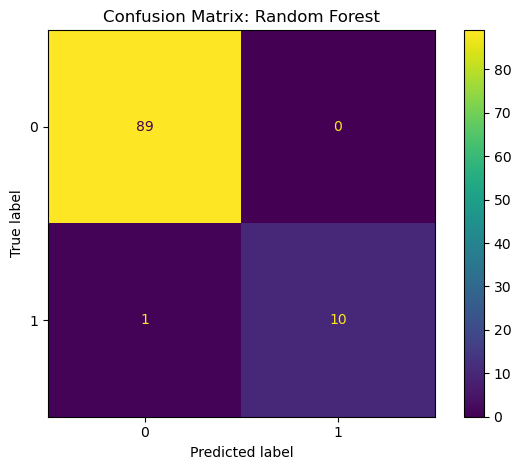

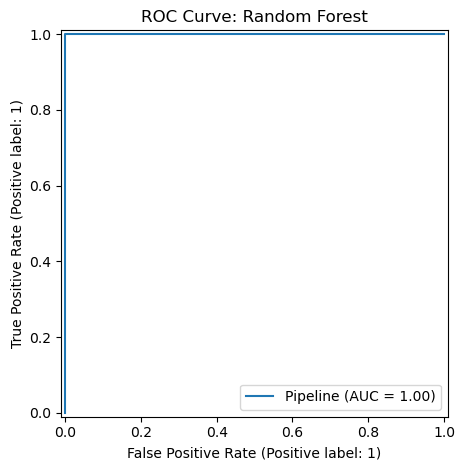

In [8]:
models={'Logistic Regression':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42),'Random Forest':RandomForestClassifier(n_estimators=300,min_samples_leaf=2,class_weight='balanced',random_state=42)}
fitted_models={}; metric_rows=[]
for name,estimator in models.items():
    pipe=Pipeline([('preprocessor',preprocessor),('model',estimator)]); pipe.fit(X_train,y_train)
    pred=pipe.predict(X_test); proba=pipe.predict_proba(X_test)[:,1]
    metric_rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0),'ROC_AUC':roc_auc_score(y_test,proba) if y_test.nunique()==2 else np.nan})
    fitted_models[name]=pipe
metrics=pd.DataFrame(metric_rows).sort_values('F1',ascending=False); display(metrics.round(3))
best_name=metrics.iloc[0]['Model']; best_model=fitted_models[best_name]; best_pred=best_model.predict(X_test)
print('Best by held-out F1 for this simple comparison:',best_name); print(classification_report(y_test,best_pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,best_pred); plt.title('Confusion Matrix: '+best_name); plt.tight_layout(); plt.show()
if y_test.nunique()==2:
    RocCurveDisplay.from_estimator(best_model,X_test,y_test); plt.title('ROC Curve: '+best_name); plt.tight_layout(); plt.show()

## 8. Feature selection and importance
Correlation and mutual information rank numeric predictors using training data. Random Forest importance is calculated on transformed features. Treat rankings as exploratory and validate feature removal with cross-validation and domain reasoning.

In [9]:
train_corr=X_train[numeric_cols].copy(); train_corr['Churn']=y_train.values
corr=train_corr.corr(numeric_only=True)['Churn'].drop('Churn').sort_values(key=lambda s:s.abs(),ascending=False)
display(corr.to_frame('correlation'))
X_num_train=X_train[numeric_cols].copy().fillna(X_train[numeric_cols].median(numeric_only=True))
mi=mutual_info_classif(X_num_train,y_train,random_state=42)
mi_report=pd.DataFrame({'feature':numeric_cols,'mutual_information':mi}).sort_values('mutual_information',ascending=False); display(mi_report)
rf_pipe=fitted_models['Random Forest']; fitted_preprocessor=rf_pipe.named_steps['preprocessor']; rf_model=rf_pipe.named_steps['model']
try:
    transformed_names=fitted_preprocessor.get_feature_names_out()
    importances=pd.DataFrame({'feature':transformed_names,'importance':rf_model.feature_importances_}).sort_values('importance',ascending=False)
    display(importances.head(15)); importances.head(15).sort_values('importance').plot(x='feature',y='importance',kind='barh',legend=False,figsize=(9,6)); plt.title('Top Random Forest Feature Importances'); plt.tight_layout(); plt.show()
except Exception as exc: print('Feature names unavailable in this scikit-learn version:',exc)

,correlation
Tenure,-0.513407
TenureYears,-0.513407
AvgHistoricalMonthlySpend,0.446810
TenureChargeInteraction,-0.367717
IsMonthToMonth,0.262582
ContractCommitmentMonths,-0.197641
HighMonthlyChargesFlag,0.127064
MonthlyCharges,0.108136
MonthlyToTotalRatio,0.036709
SeniorCitizen,-0.036048


,feature,mutual_information
0,Tenure,0.240778
4,TenureYears,0.238122
11,TenureChargeInteraction,0.141364
5,AvgHistoricalMonthlySpend,0.123258
7,ContractCommitmentMonths,0.034773
8,IsMonthToMonth,0.032474
10,PaperlessBillingFlag,0.015014
12,HighMonthlyChargesFlag,0.013681
1,MonthlyCharges,0.006002
6,MonthlyToTotalRatio,0.005782


Feature names unavailable in this scikit-learn version: Estimator outlier_clipping does not provide get_feature_names_out. Did you mean to call pipeline[:-1].get_feature_names_out()?


## 9. Automated validation and saved outputs
Run all cells top-to-bottom. Assertions check target validity, engineered feature creation, train/test separation, finite metrics, and prediction behavior with an unseen nominal category.

In [10]:
assert 'Churn' in df.columns and set(y.unique()).issubset({0,1})
assert len(engineered_cols)>=5 and set(engineered_cols).issubset(feature_df.columns)
assert len(X_train)+len(X_test)==len(X) and set(X_train.index).isdisjoint(set(X_test.index))
assert len(best_pred)==len(y_test)
assert np.isfinite(metrics[['Accuracy','Precision','Recall','F1']].to_numpy()).all()
sample=X_test.head(2).copy()
if 'PaymentMethod' in sample.columns: sample.loc[sample.index[0],'PaymentMethod']='__UNSEEN_CATEGORY__'
_ = best_model.predict(sample)
print('PASS: schema and target checks')
print('PASS: nine engineered features')
print('PASS: train/test separation')
print('PASS: finite evaluation metrics')
print('PASS: unseen-category prediction smoke test')
metrics.to_csv('model_metrics.csv',index=False); outlier_report.to_csv('outlier_report.csv',index=False)
try: importances.to_csv('feature_importance.csv',index=False)
except NameError: pass
print('Saved model_metrics.csv, outlier_report.csv, and feature_importance.csv (if supported).')

PASS: schema and target checks
PASS: nine engineered features
PASS: train/test separation
PASS: finite evaluation metrics
PASS: unseen-category prediction smoke test
Saved model_metrics.csv, outlier_report.csv, and feature_importance.csv (if supported).
